# 05 — Prédiction du type de trafic : XGBoost Regressor

**Responsable : Membre 5** · Cible : `type` (10 classes) encodée en **code ordinal** · Entrée : `data/processed/*` (notebook 01)

## Pourquoi une *régression* pour une cible nominale ?
Le sujet impose des **régresseurs** pour prédire le type. `type` est nominal : on lui donne donc un **code ordinal** défini dans `ml_utils.TYPE_ORDER`
(normal → reconnaissance → déni de service → attaques web → malware → interception), choisi a priori. **Attention** : l'étude de sensibilité du notebook 04 (§1) montre que cet ordre n'apporte pas de gain mesurable face à un ordre alphabétique ou aléatoire ; le choix d'ordre reste donc arbitraire. Le modèle prédit un **nombre** ; on retrouve la classe par **décodage** (arrondi, puis seuils optimisés).

## Workflow
1. Encodage ordinal de la cible et **sensibilité à l'ordre** choisi (voir notebook 04)
2. **Baseline**
3. **Équilibrage** : pondération des échantillons (`sample_weight`) comparée en validation croisée
4. **Réglage des hyper-paramètres** (recherche aléatoire, CV stratifiée sur `type`)
5. **Arrêt anticipé** (early stopping) et courbe d'apprentissage
6. Évaluation en validation : métriques de régression **et** de classification après décodage
7. **Calibration du décodage** : seuils entre classes optimisés sur la validation
8. **Évaluation finale unique sur le test**
9. Interprétation (importances, permutation) et analyse des erreurs par type
10. Sauvegarde pour le tableau comparatif (notebook 06)

## Métriques
- **Régression** (sur le code brut) : MAE, RMSE, R²
- **Après décodage** : accuracy, balanced accuracy, **F1 macro** (important : `mitm` ne pèse que 0,6 % des lignes), part des erreurs d'au plus **1 classe**

In [1]:
import sys, time, warnings
sys.path.append("../src")
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt, seaborn as sns
import ml_utils as U
from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, ParameterSampler, train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:.4f}".format); pd.set_option("display.max_columns", 40)
RS = U.RANDOM_STATE; K = len(U.TYPE_ORDER)
cfg = U.load_config(); NUM, CAT = cfg["numeric_cols"], cfg["categorical_cols"]
X_train, y_tr = U.load_split("train"); X_valid, y_va = U.load_split("valid"); X_test, y_te = U.load_split("test")
ytr, yva, yte = y_tr["type_code"].to_numpy(), y_va["type_code"].to_numpy(), y_te["type_code"].to_numpy()
print({"train": X_train.shape, "valid": X_valid.shape, "test": X_test.shape})
display(pd.DataFrame({"code": range(K), "type": U.TYPE_ORDER, "effectif train": np.bincount(ytr, minlength=K)}).set_index("code").T)

{'train': (110132, 33), 'valid': (36711, 33), 'test': (36711, 33)}


code,0,1,2,3,4,5,6,7,8,9
type,normal,scanning,dos,ddos,password,injection,xss,backdoor,ransomware,mitm
effectif train,25161,11169,8805,11991,11908,11975,8713,11226,8560,624


## 1. Encodage
Même encodage ordinal (`TYPE_ORDER`) que dans le notebook 04, où sa sensibilité à l'ordre est étudiée (ordre documenté / alphabétique / aléatoire).

## 2. Pipeline et pondération
Pas de standardisation (`scale=False`) : les arbres sont invariants aux transformations monotones ; `log1p` est néanmoins conservé pour la lisibilité des importances.
Les **poids** compensent le déséquilibre (§équilibrage) : `balanced` = n / (K × effectif de la classe) ; `racine` = sa racine carrée (correction adoucie).

In [2]:
def make_model(**p):
    p = {"n_estimators": 300, "learning_rate": 0.1, **p}
    return Pipeline([("pre", U.make_preprocessor(NUM, CAT, scale=False)),
                     ("model", XGBRegressor(objective="reg:squarederror", tree_method="hist", n_jobs=-1, random_state=RS, **p))])
cnt = np.bincount(ytr, minlength=K)
w_bal = (len(ytr) / (K * cnt))[ytr]; w_sqrt = np.sqrt(w_bal); w_sqrt = w_sqrt / w_sqrt.mean()
SCHEMES = {"Aucun": None, "Poids balanced": w_bal, "Poids racine (adouci)": w_sqrt}
print("Poids par classe (balanced) :", dict(zip(U.TYPE_ORDER, (len(ytr) / (K * cnt)).round(2))))
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RS)
sub = X_train.sample(40000, random_state=RS).index.to_numpy()      # sous-échantillon pour la CV / le réglage
Xs, ys, strat = X_train.loc[sub].reset_index(drop=True), ytr[sub], y_tr["type"].to_numpy()[sub]

def cv_eval(make, w=None, X=Xs, y=ys, strat_=strat):
    rows = []
    for tr, va in cv.split(X, strat_):
        t0 = time.time(); m = make()
        m.fit(X.iloc[tr], y[tr], model__sample_weight=None if w is None else w[tr]); fit_t = time.time() - t0
        rows.append({**U.regression_metrics(y[va], m.predict(X.iloc[va]), K), "fit_s": fit_t})
    return pd.DataFrame(rows).mean()

Poids par classe (balanced) : {'normal': np.float64(0.44), 'scanning': np.float64(0.99), 'dos': np.float64(1.25), 'ddos': np.float64(0.92), 'password': np.float64(0.92), 'injection': np.float64(0.92), 'xss': np.float64(1.26), 'backdoor': np.float64(0.98), 'ransomware': np.float64(1.29), 'mitm': np.float64(17.65)}


## 3. Baseline
XGBoost Regressor avec hyper-paramètres par défaut, sans pondération.

In [3]:
t0 = time.time(); base = make_model().fit(X_train, ytr); t_base = time.time() - t0
base_valid = U.regression_metrics(yva, base.predict(X_valid), K)
print(f"Temps : {t_base:.1f}s"); display(pd.Series(base_valid).to_frame("baseline (validation)").T.round(4))

Temps : 5.4s


,mae,rmse,r2,accuracy,balanced_accuracy,f1_macro,within_1_class
baseline (validation),0.0820,0.3779,0.9807,0.9679,0.8964,0.9073,0.9887


## 4. Équilibrage : pondération des échantillons
Les rééchantillonneurs classiques (SMOTE, sous-échantillonnage) travaillent sur des **classes** et ne s'appliquent pas à une cible continue.
Pour un régresseur, l'équivalent est `sample_weight` : la perte quadratique des classes rares est multipliée. Les trois schémas sont comparés en CV (poids appris **dans** chaque pli),
sur des métriques **non pondérées** pour que la comparaison reste honnête. Choix sur le **F1 macro**.

,mae,rmse,r2,accuracy,balanced_accuracy,f1_macro,within_1_class,fit_s
Aucun,0.1133,0.4447,0.9733,0.9567,0.8700,0.8726,0.9843,1.0161
Poids balanced,0.1165,0.4471,0.9731,0.9542,0.8666,0.8685,0.9841,1.0043
Poids racine (adouci),0.1150,0.4392,0.9740,0.9547,0.8666,0.8681,0.9839,1.1746


=> Schéma retenu : Aucun


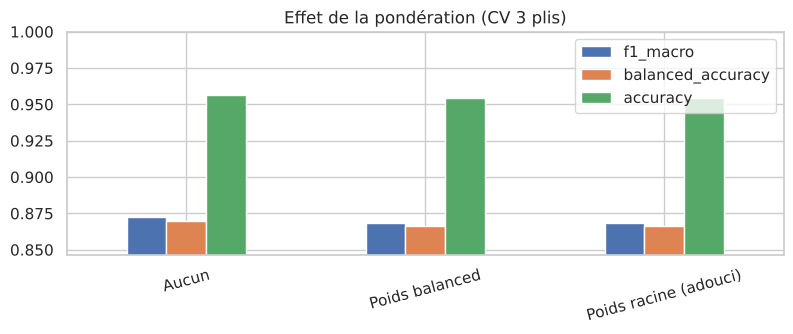

In [4]:
rows = {n: cv_eval(lambda: make_model(n_estimators=150), w) for n, w in SCHEMES.items()}
wtab = pd.DataFrame(rows).T; display(wtab[["mae", "rmse", "r2", "accuracy", "balanced_accuracy", "f1_macro", "within_1_class", "fit_s"]].round(4))
best_scheme = wtab["f1_macro"].idxmax(); w_best = SCHEMES[best_scheme]; print(f"=> Schéma retenu : {best_scheme}")
fig, ax = plt.subplots(figsize=(8, 3.5)); wtab[["f1_macro", "balanced_accuracy", "accuracy"]].plot(kind="bar", ax=ax); ax.set_ylim(wtab[["f1_macro", "balanced_accuracy", "accuracy"]].min().min() - .02, 1)
ax.set_title("Effet de la pondération (CV 3 plis)"); ax.tick_params(axis="x", rotation=15); plt.tight_layout(); U.savefig(fig, "05_weighting"); plt.show()

## 5. Réglage des hyper-paramètres
Recherche aléatoire (12 configurations × 3 plis) sur le sous-échantillon, avec le schéma de poids retenu. Classement par **RMSE** (perte native de la régression) ; le F1 macro est affiché en parallèle.
Le nombre d'arbres est fixé à 300 pendant la recherche puis déterminé précisément par arrêt anticipé.

In [5]:
space = {"max_depth": [4, 6, 8, 10], "learning_rate": [0.03, 0.06, 0.1, 0.2], "subsample": [0.7, 0.85, 1.0], "colsample_bytree": [0.5, 0.7, 0.9, 1.0], "min_child_weight": [1, 3, 5, 10], "reg_lambda": [0.5, 1, 5, 10], "gamma": [0, 0.1, 0.5]}
fixed = {"n_estimators": 150}
configs, rows = [], []
for i, p in enumerate(ParameterSampler(space, n_iter=12, random_state=RS)):
    p = {k: (v.item() if hasattr(v, "item") else v) for k, v in p.items()}
    r = cv_eval(lambda: make_model(**{**fixed, **p}), w_best); configs.append(p)
    rows.append({**{k: str(v) for k, v in p.items()}, "rmse": r["rmse"], "f1_macro": r["f1_macro"], "accuracy": r["accuracy"], "fit_s": r["fit_s"]})
    print(f"  [{i+1}/12] rmse={r['rmse']:.4f} f1_macro={r['f1_macro']:.4f}  {p}")
tuning = pd.DataFrame(rows).sort_values("rmse"); display(tuning.head(8).round(4))
best_params = configs[int(tuning.index[0])]; print("Meilleurs hyper-paramètres :", best_params)

  [1/12] rmse=0.4268 f1_macro=0.8779  {'subsample': 0.85, 'reg_lambda': 10, 'min_child_weight': 3, 'max_depth': 10, 'learning_rate': 0.06, 'gamma': 0, 'colsample_bytree': 1.0}


  [2/12] rmse=0.5327 f1_macro=0.8233  {'subsample': 1.0, 'reg_lambda': 5, 'min_child_weight': 10, 'max_depth': 6, 'learning_rate': 0.03, 'gamma': 0.1, 'colsample_bytree': 0.5}


  [3/12] rmse=0.6711 f1_macro=0.7321  {'subsample': 1.0, 'reg_lambda': 0.5, 'min_child_weight': 3, 'max_depth': 4, 'learning_rate': 0.03, 'gamma': 0.1, 'colsample_bytree': 0.9}


  [4/12] rmse=0.4979 f1_macro=0.8406  {'subsample': 0.85, 'reg_lambda': 5, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.2, 'gamma': 0, 'colsample_bytree': 0.9}


  [5/12] rmse=0.4237 f1_macro=0.8687  {'subsample': 0.85, 'reg_lambda': 10, 'min_child_weight': 3, 'max_depth': 10, 'learning_rate': 0.06, 'gamma': 0.1, 'colsample_bytree': 0.9}


  [6/12] rmse=0.4519 f1_macro=0.8619  {'subsample': 0.85, 'reg_lambda': 0.5, 'min_child_weight': 5, 'max_depth': 8, 'learning_rate': 0.03, 'gamma': 0.5, 'colsample_bytree': 0.9}


... (4 outputs left out)

  [11/12] rmse=0.4231 f1_macro=0.8675  {'subsample': 1.0, 'reg_lambda': 1, 'min_child_weight': 1, 'max_depth': 10, 'learning_rate': 0.03, 'gamma': 0.5, 'colsample_bytree': 0.5}


  [12/12] rmse=0.6647 f1_macro=0.7262  {'subsample': 0.85, 'reg_lambda': 0.5, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.03, 'gamma': 0.1, 'colsample_bytree': 0.5}


,subsample,reg_lambda,min_child_weight,max_depth,learning_rate,gamma,colsample_bytree,rmse,f1_macro,accuracy,fit_s
10,1.0,1,1,10,0.03,0.5,0.5,0.4231,0.8675,0.9601,1.6353
4,0.85,10,3,10,0.06,0.1,0.9,0.4237,0.8687,0.9614,1.4918
0,0.85,10,3,10,0.06,0,1.0,0.4268,0.8779,0.9619,1.7730
9,0.7,5,3,6,0.2,0.1,1.0,0.4395,0.8828,0.9568,0.9300
5,0.85,0.5,5,8,0.03,0.5,0.9,0.4519,0.8619,0.9520,1.4570
6,0.85,10,5,6,0.1,0,0.5,0.4647,0.8516,0.9457,0.8437
3,0.85,5,1,4,0.2,0,0.9,0.4979,0.8406,0.9335,0.7189
7,0.85,10,1,4,0.2,0.5,0.7,0.5067,0.8433,0.9364,0.7616


Meilleurs hyper-paramètres : {'subsample': 1.0, 'reg_lambda': 1, 'min_child_weight': 1, 'max_depth': 10, 'learning_rate': 0.03, 'gamma': 0.5, 'colsample_bytree': 0.5}


## 6. Arrêt anticipé et modèle final
Un jeu de contrôle (10 % du train, stratifié) sert à arrêter l'ajout d'arbres quand l'erreur ne baisse plus pendant 50 itérations — **pas** la validation, réservée au calibrage.

Nombre d'arbres retenu (early stopping) : 2000


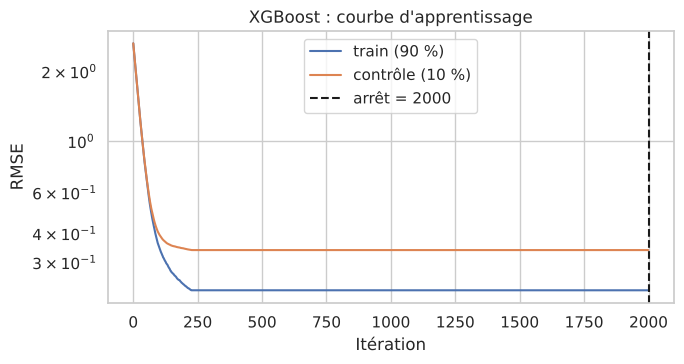

Réentraînement sur tout le train : 15.9s


In [6]:
tr_i, ho_i = train_test_split(np.arange(len(X_train)), test_size=0.10, stratify=y_tr["type"], random_state=RS)
pre_es = U.make_preprocessor(NUM, CAT, scale=False).fit(X_train.iloc[tr_i])
Xa, Xb = pre_es.transform(X_train.iloc[tr_i]), pre_es.transform(X_train.iloc[ho_i])
kw = {} if w_best is None else {"sample_weight": w_best[tr_i], "sample_weight_eval_set": [w_best[tr_i], w_best[ho_i]]}
es = XGBRegressor(n_estimators=2000, early_stopping_rounds=50, eval_metric="rmse", objective="reg:squarederror", tree_method="hist", n_jobs=-1, random_state=RS, **{k: v for k, v in best_params.items() if k != "n_estimators"})
es.fit(Xa, ytr[tr_i], eval_set=[(Xa, ytr[tr_i]), (Xb, ytr[ho_i])], verbose=False, **kw)
best_n = int(es.best_iteration) + 1; print(f"Nombre d'arbres retenu (early stopping) : {best_n}")
hist = es.evals_result(); fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(hist["validation_0"]["rmse"], label="train (90 %)"); ax.plot(hist["validation_1"]["rmse"], label="contrôle (10 %)"); ax.axvline(best_n, color="k", ls="--", label=f"arrêt = {best_n}")
ax.set(xlabel="Itération", ylabel="RMSE", title="XGBoost : courbe d'apprentissage", yscale="log"); ax.legend(); plt.tight_layout(); U.savefig(fig, "05_learning_curve"); plt.show()
best_params["n_estimators"] = best_n
t0 = time.time(); final = make_model(**best_params).fit(X_train, ytr, model__sample_weight=w_best); t_fit = time.time() - t0; print(f"Réentraînement sur tout le train : {t_fit:.1f}s")

## 7. Évaluation en validation

,mae,rmse,r2,accuracy,balanced_accuracy,f1_macro,within_1_class
train,0.0558,0.2291,0.9929,0.9769,0.9053,0.9174,0.9934
validation,0.0743,0.3626,0.9822,0.9710,0.8915,0.8992,0.9886


              precision    recall  f1-score   support

      normal      1.000     0.984     0.992      8387
    scanning      0.971     0.971     0.971      3723
         dos      0.949     0.976     0.962      2935
        ddos      0.983     0.953     0.968      3997
    password      0.958     0.986     0.972      3969
   injection      0.924     0.972     0.947      3992
         xss      0.955     0.928     0.941      2905
    backdoor      0.982     0.999     0.990      3742
  ransomware      0.984     0.997     0.991      2853
        mitm      0.969     0.149     0.258       208

    accuracy                          0.971     36711
   macro avg      0.967     0.892     0.899     36711
weighted avg      0.971     0.971     0.969     36711



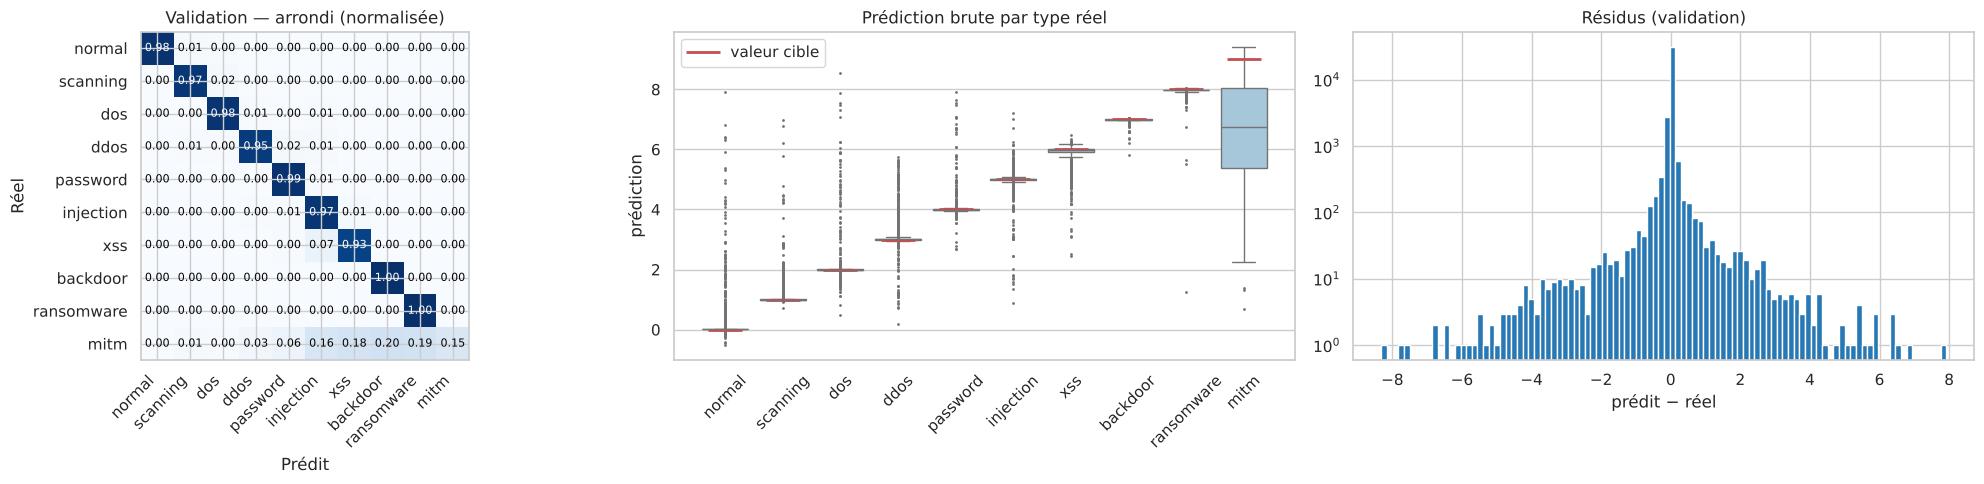

In [7]:
p_tr, p_va = final.predict(X_train), final.predict(X_valid)
rm_tr, rm_va = U.regression_metrics(ytr, p_tr, K), U.regression_metrics(yva, p_va, K)
display(pd.DataFrame({"train": rm_tr, "validation": rm_va}).T.round(4))
pred_va = np.clip(np.rint(p_va), 0, K - 1).astype(int)
print(classification_report(yva, pred_va, target_names=U.TYPE_ORDER, digits=3, zero_division=0))
fig, axes = plt.subplots(1, 3, figsize=(21, 5))
U.plot_confusion(confusion_matrix(yva, pred_va, labels=range(K)), U.TYPE_ORDER, "Validation — arrondi (normalisée)", ax=axes[0], normalize=True)
sns.boxplot(x=pd.Categorical(y_va["type"], U.TYPE_ORDER), y=p_va, ax=axes[1], fliersize=1, color="#9ecae1"); axes[1].plot(range(K), range(K), "r_", ms=25, mew=2, label="valeur cible")
axes[1].set(title="Prédiction brute par type réel", xlabel="", ylabel="prédiction"); axes[1].tick_params(axis="x", rotation=45); axes[1].legend()
axes[2].hist(p_va - yva, bins=100, color="#2878b5"); axes[2].set(title="Résidus (validation)", xlabel="prédit − réel", yscale="log")
plt.tight_layout(); U.savefig(fig, "05_valid_eval"); plt.show()

## 8. Calibration du décodage (seuils entre classes)
L'arrondi place les frontières à 0,5 ; 1,5 ; … Rien ne garantit qu'elles soient optimales (classes rares, erreurs asymétriques).
On cherche donc les **9 seuils** qui maximisent le F1 macro **sur la validation**, par descente de coordonnées, puis on les applique tels quels au test.

In [8]:
cuts, f1_cut = U.optimize_cutpoints(p_va, yva, K)
print("Seuils optimisés :", cuts.round(3)); print("Seuils par défaut:", (np.arange(K - 1) + .5))
pv_round = U.decode_with_cuts(p_va, np.arange(K - 1) + .5); pv_cut = U.decode_with_cuts(p_va, cuts)
cmp_ = pd.DataFrame({"arrondi": U.regression_metrics_from_classes(yva, p_va, pv_round, K), "seuils optimisés": U.regression_metrics_from_classes(yva, p_va, pv_cut, K)}).T
display(cmp_[["accuracy", "balanced_accuracy", "f1_macro", "within_1_class"]].round(4))

Seuils optimisés : [0.933 1.785 2.29  3.803 4.376 5.226 6.306 7.293 8.039]
Seuils par défaut: [0.5 1.5 2.5 3.5 4.5 5.5 6.5 7.5 8.5]


,accuracy,balanced_accuracy,f1_macro,within_1_class
arrondi,0.9710,0.8915,0.8992,0.9886
seuils optimisés,0.9766,0.9076,0.9194,0.9886


## 9. Évaluation finale sur le test (une seule fois)

,mae,rmse,r2,accuracy,balanced_accuracy,f1_macro,within_1_class
arrondi,0.0738,0.3559,0.9829,0.9718,0.8928,0.9009,0.9888
seuils optimisés (valid),0.0738,0.3559,0.9829,0.9761,0.9099,0.9225,0.9887


              precision    recall  f1-score   support

      normal      0.999     0.990     0.994      8387
    scanning      0.976     0.984     0.980      3723
         dos      0.974     0.968     0.971      2935
        ddos      0.976     0.956     0.966      3997
    password      0.977     0.984     0.981      3970
   injection      0.950     0.961     0.956      3992
         xss      0.931     0.970     0.950      2904
    backdoor      0.980     0.999     0.990      3742
  ransomware      0.990     0.998     0.994      2853
        mitm      0.952     0.288     0.443       208

    accuracy                          0.976     36711
   macro avg      0.971     0.910     0.922     36711
weighted avg      0.976     0.976     0.975     36711



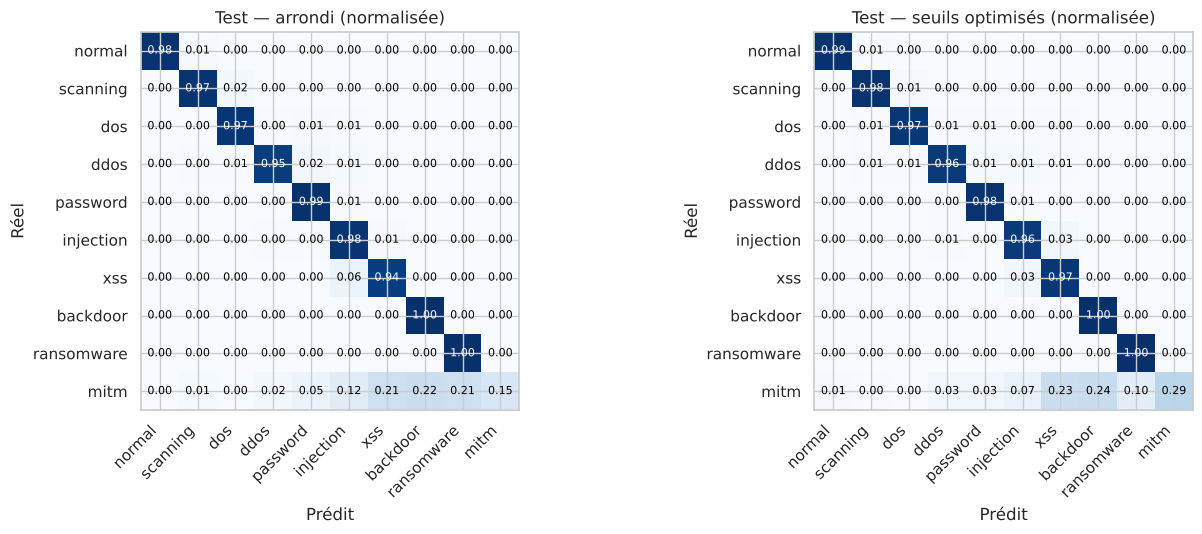

In [9]:
p_te = final.predict(X_test)
pt_round, pt_cut = U.decode_with_cuts(p_te, np.arange(K - 1) + .5), U.decode_with_cuts(p_te, cuts)
test_tbl = pd.DataFrame({"arrondi": U.regression_metrics_from_classes(yte, p_te, pt_round, K), "seuils optimisés (valid)": U.regression_metrics_from_classes(yte, p_te, pt_cut, K)}).T
display(test_tbl[["mae", "rmse", "r2", "accuracy", "balanced_accuracy", "f1_macro", "within_1_class"]].round(4))
print(classification_report(yte, pt_cut, target_names=U.TYPE_ORDER, digits=3, zero_division=0))
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
U.plot_confusion(confusion_matrix(yte, pt_round, labels=range(K)), U.TYPE_ORDER, "Test — arrondi (normalisée)", ax=axes[0], normalize=True)
U.plot_confusion(confusion_matrix(yte, pt_cut, labels=range(K)), U.TYPE_ORDER, "Test — seuils optimisés (normalisée)", ax=axes[1], normalize=True)
plt.tight_layout(); U.savefig(fig, "05_test_confusions"); plt.show()

## 10. Interprétation et analyse des erreurs

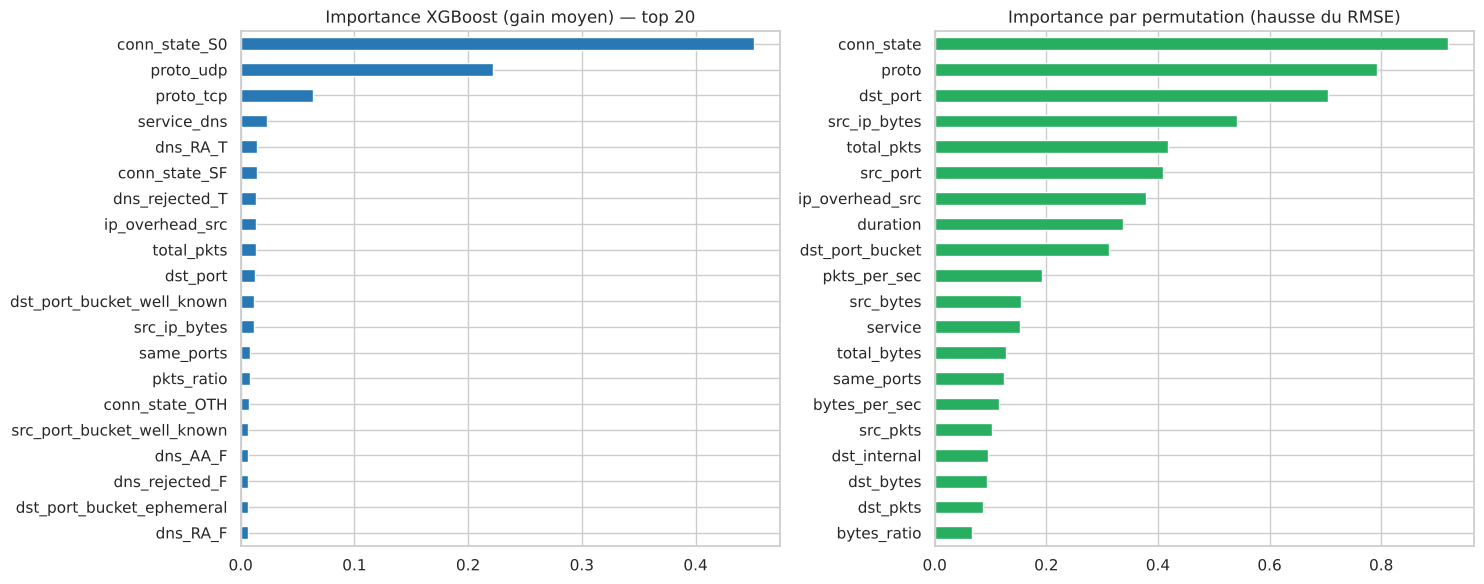

In [10]:
imp = pd.Series(final.named_steps["model"].feature_importances_, index=U.feature_names(final.named_steps["pre"])).sort_values(ascending=False)
imp_title = "Importance XGBoost (gain moyen) — top 20"
sidx = X_valid.sample(6000, random_state=RS).index
pi = permutation_importance(final, X_valid.loc[sidx], yva[sidx.to_numpy()], scoring="neg_root_mean_squared_error", n_repeats=3, random_state=RS, n_jobs=1)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
imp.head(20).iloc[::-1].plot(kind="barh", ax=axes[0], color="#2878b5"); axes[0].set_title(imp_title)
pd.Series(pi.importances_mean, index=X_valid.columns).sort_values().tail(20).plot(kind="barh", ax=axes[1], color="#27ae60"); axes[1].set_title("Importance par permutation (hausse du RMSE)")
plt.tight_layout(); U.savefig(fig, "05_importances"); plt.show()

,n,MAE,rappel,erreur_>1_classe
type,,,,
normal,8387.0000,0.0447,0.9895,0.0055
scanning,3723.0000,0.0617,0.9836,0.0073
dos,2935.0000,0.0817,0.9683,0.0184
ddos,3997.0000,0.1066,0.9565,0.0250
password,3970.0000,0.0464,0.9844,0.0043
injection,3992.0000,0.0782,0.9614,0.0093
xss,2904.0000,0.1127,0.9704,0.0010
backdoor,3742.0000,0.0140,0.9992,0.0000
ransomware,2853.0000,0.0320,0.9975,0.0011


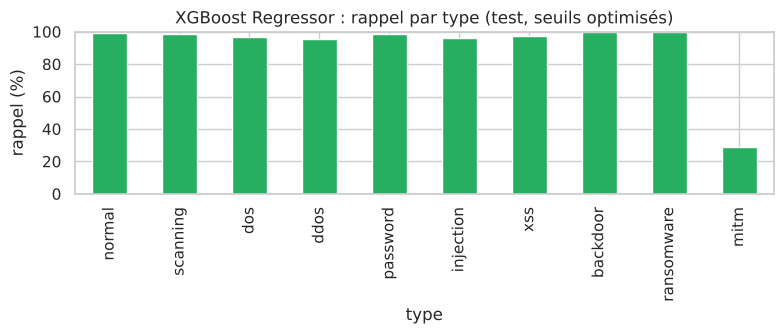

In [11]:
d = pd.DataFrame({"type": y_te["type"].to_numpy(), "code": yte, "pred": p_te, "cls": pt_cut})
by_type = d.groupby("type").apply(lambda g: pd.Series({"n": len(g), "MAE": np.abs(g.pred - g.code).mean(), "rappel": (g.cls == g.code).mean(), "erreur_>1_classe": (np.abs(g.cls - g.code) > 1).mean()})).loc[U.TYPE_ORDER]
display(by_type.round(4))
fig, ax = plt.subplots(figsize=(8, 3.5)); by_type["rappel"].mul(100).plot(kind="bar", ax=ax, color="#27ae60"); ax.set(ylabel="rappel (%)", title="XGBoost Regressor : rappel par type (test, seuils optimisés)"); ax.set_ylim(0, 100)
plt.tight_layout(); U.savefig(fig, "05_recall_by_type"); plt.show()

## 11. Sauvegarde

In [12]:
joblib.dump(final, U.MODEL_DIR / "xgb_type_regressor.joblib", compress=3)
U.save_result("05_xgb_regressor", {"task": "Prédiction du type", "model": "XGBoost Regressor", "weighting": best_scheme, "params": best_params, "cutpoints": cuts.tolist(), "fit_time_s": t_fit,
    "valid_f1_macro_cuts": f1_cut, "test_rounded": {k: float(v) for k, v in test_tbl.loc["arrondi"].items()},
    "test": {k: float(v) for k, v in test_tbl.loc["seuils optimisés (valid)"].items()}, "weighting_cv": wtab.round(5).to_dict("index"), "recall_by_type": by_type["rappel"].to_dict()})
print("Modèle et résultats sauvegardés.")

Modèle et résultats sauvegardés.


## Conclusion (XGBoost Regressor — prédiction du type)

- La cible nominale est traitée comme un **code ordinal** documenté.
- L'équilibrage passe par `sample_weight`, choisi en **validation croisée** sur le F1 macro.
- Les **seuils de décodage** sont calibrés sur la validation ; le test n'est lu qu'une fois.
- Limite à assumer : un **classifieur multi-classes** serait plus naturel pour un type nominal ; l'étude de sensibilité (notebook 04, §1) n'a pas montré que l'ordre choisi soit meilleur qu'un ordre aléatoire, ce qui renforce cette recommandation.
- Valeurs chiffrées : §9 (test) et notebook 06.